# Image Processing Warm-up

This notebook introduces the fundamentals of image manipulation using NumPy, Matplotlib and OpenCV.

Before training complex models, it is important to understand how images can be manipulated mathematically.

**Setting up the environment**

- Install the required libraries:

```shell 
%pip install numpy matplotlib opencv-python
```

## Import Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

## Create a Function to Display Images

In [6]:
def Show(img, title=None):
    plt.figure()

    if title is not None:
        plt.title(title)

    plt.imshow(img, cmap='gray')
    plt.axis("off")
    plt.show()

**Understanding the code:**

* `plt.figure()` creates a new figure. 

* `plt.title` adds a title.

* `plt.imshow()` displays the image.

* `cmap='gray'` display the image in grayscale.

* `plt.axis("off")` removes the coordinate axes.

* `plt.show()` displays the final result.

Creating a function saves us from repeatedly writing the same image-display code.

## Creating a synthetic image
A synthetic image is an image generated programmatically rather than captured using a camera.

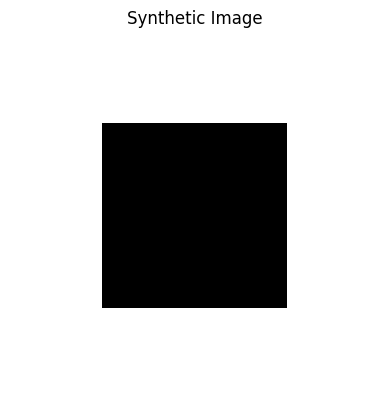

In [4]:
Ysize = 64
Xsize = 64

img = np.ones((Ysize, Xsize), dtype=float)

img[16:48, 16:48] = 0

Show(img, 'Synthetic Image')

A white image with a black square.

**Step-by-step explanation:**

1. Ysize defines the image height.

2. Xsize defines the image width.

3. np.ones() creates an array filled with ones.

4. The array initially represents a completely white image.

5. img[16:48, 16:48] = 0 changes a section of the image to black.

The image has:
$$
64 \times 64 = 4096 \text{ pixels}
$$

The black square occupies:
$$
32 \times 32 = 1024 \text{ pixels}
$$

The black square occupies:

* Canvas Creation: np.ones((64, 64), dtype=float) creates a 64 × 64 grid filled entirely with 1.0 (which renders as white).

* Row Height (Y-axis): The slice 16:48 selects rows starting at index 16 up to index 47. Subtracting the bounds gives a height of 48 - 16 = 32 pixels.

* Column Width (X-axis): The second slice 16:48 selects columns from index 16 up to 47. Subtracting the bounds gives a width of 48 - 16 = 32 pixels.

* Color Assignment: Setting those selected pixels to 0 turns that 32 × 32 region black.

* Total Area: Multiplying the height and width of the modified region yields 32 × 32 = 1,024 pixels.

## Inverting an Image
Image inversion reverses the intensity values.

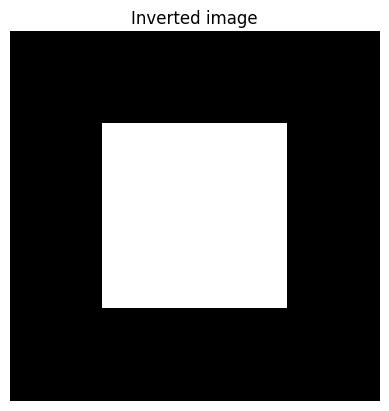

In [7]:
img_inverted = 1.0 - img

Show(img_inverted, 'Inverted image')

What happens?

- White (1) becomes black (0).

- Black (0) becomes white (1).

- Grey values are also reversed.

Mathematical representation:
$$
I_{\text{new}} = 1-I_{\text{original}}
$$

Why is this useful?

Image inversion can help reveal details in certain images and is useful in image enhancement and preprocessing.

## Adding noise to an image

### What is image noise?
Image noise refers to random variations in pixel intensity that can make an image appear grainy or distorted.

Noise can occur because of:
- Poor lighting.

- Camera sensor limitations.

- Transmission errors.

- Environmental interference.

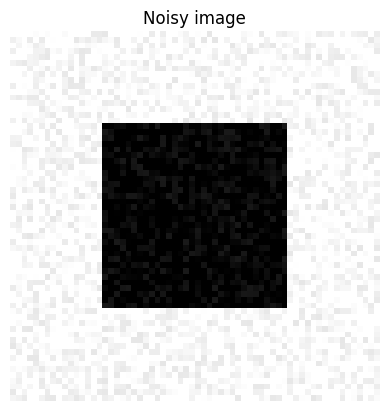

In [10]:
np.random.seed(0)

noise = 0.2 * (np.random.rand(Ysize, Xsize) - 0.5)

img_noisy = np.clip(
    img + noise,
    0.0,
    1.0
)

Show(img_noisy, 'Noisy image')

Understanding the code:

- `np.random.seed(0)` ensures reproducible random values.

- `np.random.rand()` generates random values between 0 and 1.

- `Subtracting 0.5` shifts the range to -0.5 and 0.5.

- `Multiplying by 0.2` controls the noise intensity.

- Adding noise modifies the original pixels.

- `np.clip()` ensures values remain between 0 and 1.

**Experiment: Increase the noise**

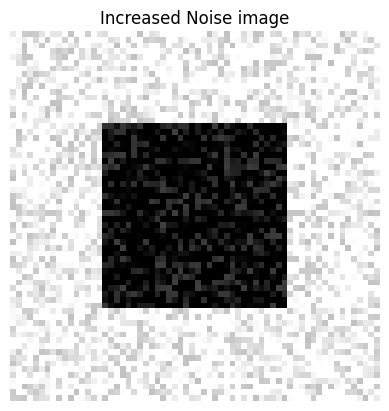

In [13]:
noise = 0.5 * (np.random.rand(Ysize, Xsize) - 0.5)
img_noisy = np.clip(
    img + noise,
    0.0,
    1.0
)

Show(img_noisy, 'Increased Noise image')

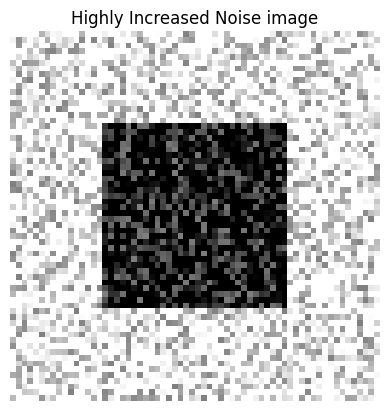

In [14]:
noise = 1.0 * (np.random.rand(Ysize, Xsize) - 0.5)

img_noisy = np.clip(
    img + noise,
    0.0,
    1.0
)

Show(img_noisy, 'Highly Increased Noise image')

| Noise level | Expected appearance |
| --- | --- |
| 0.2 | Slightly noisy |
| 0.5 | More visible distortion |
| 1.0 | Significant distortion |

**Important**: 

As noise increases, image quality decreases, making it more difficult for computer vision models to identify useful features.

## Image smoothing and blurring

### What is image smoothing?
Image smoothing is a technique used to reduce noise and small variations in an image.
M
- One common method is an averaging `filter`.

- The filter replaces each pixel with the average of the neighbouring pixels.

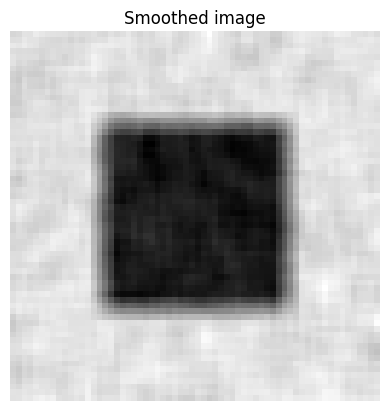

In [16]:
kernel = np.ones((5, 5), dtype=float) / 25.0

img_smooth = cv.filter2D(
    img_noisy,
    -1,
    kernel
)

Show(img_smooth, 'Smoothed image')

**Understanding the kernel:**

```bash
np.ones((5, 5)) / 25
```

Creates a matrix containing 25 equal values.

Each value is:
$$
\frac{1}{25}=0.04
$$

The filter calculates the average of a 5 × 5 neighbourhood.

- The filter2D() function applies this kernel to the image.

<img src="img/noise.png" alt="Noise Image" width="500">
<p><strong>Noise Image</strong></p>

<img src="img/filter.png" alt="Filter Image" width="500">
<p><strong>Filter Image</strong></p>

<img src="img/box_filter_smoothing.png" alt="Box Filter Smoothing Image" width="500">
<p><strong>Box Filter Smoothing Image</strong></p>

## Understanding the BlurBox function

In [17]:
def BlurBox(img, r):

    res = np.ones_like(img)

    m, n = res.shape

    for i in range(r, m - 1 - r):

        for k in range(r, n - 1 - r):

            res[i, k] = np.mean(
                img[
                    i-r:i+r+1,
                    k-r:k+r+1
                ]
            )

    return res

**Breaking this down.**

1. Create an output image

```bash
res = np.ones_like(img)
```

Creates an array with the same dimensions as the original image.

2. Obtain the image dimensions

```bash
m, n = res.shape
```

* m = Number of rows.
* n = Number of columns.

3. Loop through the pixels

```bash
for i in range(r, m - 1 - r):
    for k in range(r, n - 1 - r):
```

Moves through the image while avoiding pixels whose neighbourhood would extend beyond the image boundaries.

4. Calculate the average

```bash 
np.mean(img[i-r:i+r+1, k-r:k+r+1])
```



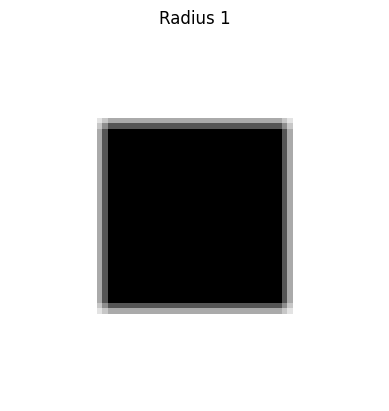

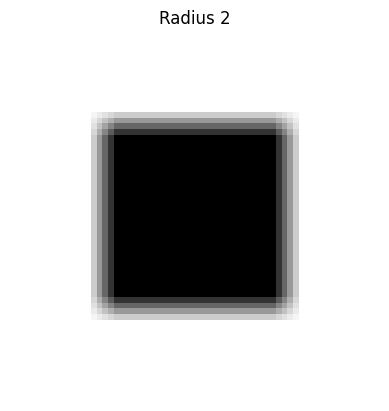

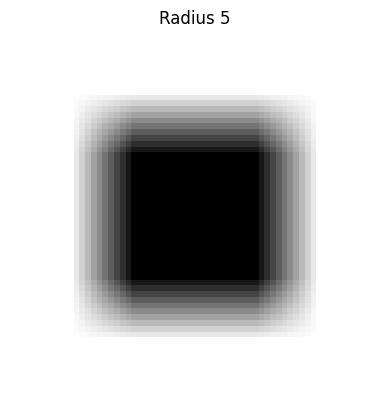

In [19]:
Show(BlurBox(img, 1), 'Radius 1')
Show(BlurBox(img, 2), 'Radius 2')
Show(BlurBox(img, 5), 'Radius 5')